Combine processed NDVI data and fit DLC curves to the data.

In [ ]:
import rasterio
import xarray as xr
import glob
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import re

from rasterio.merge import merge
from rasterio.transform import from_bounds
from datetime import datetime, timedelta
from scipy.optimize import curve_fit
from rasterio.transform import rowcol

# Step 1: Load GeoTIFF files and group by year
folder_path = "H:/My Drive/NDVI_Exports"  # Path to your folder with GeoTIFF files
tile_files = glob.glob(os.path.join(folder_path, "*.tif"))

# Group files by year using regex
file_groups = {}
for tile in tile_files:
    match = re.search(r'(\d{4})', tile)  # Assuming the year is in the filename
    if match:
        year = int(match.group(1))
        if year not in file_groups:
            file_groups[year] = []
        file_groups[year].append(tile)

src_files = [rasterio.open(tile) for tile in year_files]

# Step 2: Merge tiles for each year
yearly_data = []
years = sorted(file_groups.keys())  # Ensure years are sorted for consistency
# years = [2018, 2019, 2020, 2021]

for year in years:
    print(f"Processing year: {year}")
    year_files = file_groups[year]
    
    # Merge all tiles for the current year
    src_files = [rasterio.open(tile) for tile in year_files]
    mosaic_array, mosaic_transform = merge(src_files)
    meta = src_files[0].meta.copy()
    meta.update({
        "driver": "GTiff",
        "height": mosaic_array.shape[1],
        "width": mosaic_array.shape[2],
        "transform": mosaic_transform,
        "crs": src_files[0].crs
    })

    # Close the individual tile files
    for src in src_files:
        src.close()

    # Store the yearly mosaic
    yearly_data.append((mosaic_array, meta))


# Step 3: Stack yearly mosaics
# Ensure all yearly mosaics have consistent dimensions
height, width = yearly_data[0][0].shape[1:]  # Use the first year's dimensions
all_years_stacked = np.empty((46 * len(years), height, width))  # 46 bands per year

for i, (mosaic, meta) in enumerate(yearly_data):
    all_years_stacked[i * 46:(i + 1) * 46, :, :] = mosaic

print("All Years Stacked Shape:", all_years_stacked.shape)  # (46 * num_years, height, width)

# Assign time coordinates
dates = []
for year in years:
    start_date = datetime(year, 1, 1)
    dates.extend([start_date + timedelta(days=8 * i) for i in range(46)])

print("Total Time Steps:", len(dates))  # Should match the number of bands

# Create an xarray.DataArray and assign time coordinates
mosaic_da = xr.DataArray(
    all_years_stacked,
    dims=("band", "y", "x"),
    name="NDVI"
)

mosaic_ds = mosaic_da.to_dataset(name="NDVI").assign_coords(band=("band", dates))

# Print the dataset summary
print(mosaic_ds)


Processing year: 2018
All Years Stacked Shape: (46, 181, 511)
Total Time Steps: 46
<xarray.Dataset> Size: 34MB
Dimensions:  (band: 46, y: 181, x: 511)
Coordinates:
  * band     (band) datetime64[ns] 368B 2018-01-01 2018-01-09 ... 2018-12-27
Dimensions without coordinates: y, x
Data variables:
    NDVI     (band, y, x) float64 34MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0


In [84]:
# Extract CRS and extent from the first year's metadata
meta = yearly_data[0][1]  # Use metadata from the first year's mosaic

# Get CRS
crs = meta["crs"]

# Calculate extent
transform = meta["transform"]
height, width = meta["height"], meta["width"]

min_x = transform[2]
max_y = transform[5]
max_x = min_x + width * transform[0]  # transform[0] is the pixel width
min_y = max_y + height * transform[4]  # transform[4] is the negative pixel height

extent = (min_x, min_y, max_x, max_y)  # (left, bottom, right, top)
transform = from_bounds(min_x, min_y, max_x, max_y, width, height)


# Print results
print("CRS:", crs)
print("Extent (Left, Bottom, Right, Top):", extent)

# Add CRS and extent to mosaic_ds attributes
mosaic_ds.attrs["crs"] = str(crs)
mosaic_ds.attrs["extent"] = extent
mosaic_ds.attrs["transform"] = transform

# Verify
print("CRS:", mosaic_ds.attrs["crs"])
print("Extent:", mosaic_ds.attrs["extent"])
print("Extent:", mosaic_ds.attrs["transform"])

mosaic_att = mosaic_ds
print("Attributes:", mosaic_att.attrs)  # CRS, transform, etc.



CRS: PROJCS["MODIS Sinusoidal",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Sinusoidal"],PARAMETER["longitude_of_center",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Extent (Left, Bottom, Right, Top): (-10023075.653006682, 4099854.228555534, -9904699.2539338, 4141784.0294013103)
CRS: PROJCS["MODIS Sinusoidal",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Sinusoidal"],PARAMETER["longitude_of_center",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","900

In [85]:
# Convert the stacked array (multi-year) to an xarray DataArray
mosaic_da = xr.DataArray(
    all_years_stacked,  # Use the multi-year stacked array
    dims=("band", "y", "x"),  # Dimensions: time (bands), rows (y), columns (x)
    name="NDVI",
    attrs={  # Basic attributes for metadata
        "crs": meta["crs"],
        "transform": meta["transform"],
        "description": "NDVI 8-day composites for multiple years"
    }
)

# Assign the time coordinates (dates) to the band dimension
mosaic_da = mosaic_da.assign_coords(band=("band", dates))

# Wrap the DataArray in an xarray Dataset for easier handling
mosaic_ds = mosaic_da.to_dataset(name="NDVI")

# Inspect the structure (dimensions, attributes, etc.)
print(mosaic_ds)
print("Dimensions:", mosaic_ds.dims)  # Should include 'band', 'y', 'x'
print("Variables:", mosaic_ds.data_vars)  # Should include 'NDVI'
print("Attributes:", mosaic_ds.attrs)  # CRS, transform, etc.

# Access the names of each layer (corresponds to "band" dimension)
print("Number of Bands (days):", mosaic_ds.dims['band'])  # Should equal 46 * num_years


<xarray.Dataset> Size: 34MB
Dimensions:  (band: 46, y: 181, x: 511)
Coordinates:
  * band     (band) datetime64[ns] 368B 2018-01-01 2018-01-09 ... 2018-12-27
Dimensions without coordinates: y, x
Data variables:
    NDVI     (band, y, x) float64 34MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
Dimensions: FrozenMappingWarningOnValuesAccess({'band': 46, 'y': 181, 'x': 511})
Variables: Data variables:
    NDVI     (band, y, x) float64 34MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
Attributes: {}
Number of Bands (days): 46


C:\Users\tlasharr\AppData\Local\Temp\ipykernel_29052\1418377606.py:26: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print("Number of Bands (days):", mosaic_ds.dims['band'])  # Should equal 46 * num_years


In [86]:
##  convert to an np array
stacked_data = np.stack([mosaic_ds['NDVI'].isel(band=i).values for i in range(mosaic_ds.dims['band'])], axis=0)
print(stacked_data.shape)  # number_of_bands, height, width

## replace all-NaN pixels
valid_mask = ~np.isnan(stacked_data).all(axis=0)  # Mask for valid pixels
min_val = np.full(stacked_data.shape[1:], np.nan)  # Default to NaN
upper_quantile = np.full(stacked_data.shape[1:], np.nan)

## only compute for valid pixels
min_val[valid_mask] = np.nanmin(stacked_data[:, valid_mask], axis=0)
upper_quantile[valid_mask] = np.nanquantile(stacked_data[:, valid_mask], 0.975, axis=0)

## fill remaining NaNs with defaults
min_val = np.nan_to_num(min_val, nan=0.0)
upper_quantile = np.nan_to_num(upper_quantile, nan=1.0)

## expand arrays for broadcasting
upper_quantile_expanded = upper_quantile[np.newaxis, :, :]
min_val_expanded = min_val[np.newaxis, :, :]

## scale NDVI values
epsilon = 1e-10
denominator = upper_quantile_expanded - min_val_expanded + epsilon
scaled_data = (stacked_data - min_val_expanded) / denominator
scaled_data = np.clip(scaled_data, 0, 1)  # Ensure scaled values stay within [0, 1]

## verify the range of scaled data
print("Scaled Data Min:", np.nanmin(scaled_data))
print("Scaled Data Max:", np.nanmax(scaled_data))
print("Upper Quantile (97.5th percentile):", np.nanmax(upper_quantile))
print("Minimum NDVI (per pixel):", np.nanmin(min_val))

(46, 181, 511)


C:\Users\tlasharr\AppData\Local\Temp\ipykernel_29052\1229002701.py:2: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  stacked_data = np.stack([mosaic_ds['NDVI'].isel(band=i).values for i in range(mosaic_ds.dims['band'])], axis=0)


Scaled Data Min: 0.0
Scaled Data Max: 1.0
Upper Quantile (97.5th percentile): 1.0
Minimum NDVI (per pixel): 0.0


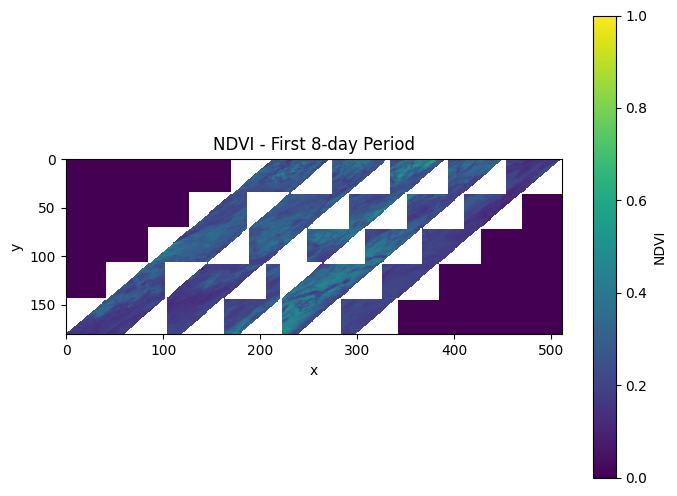

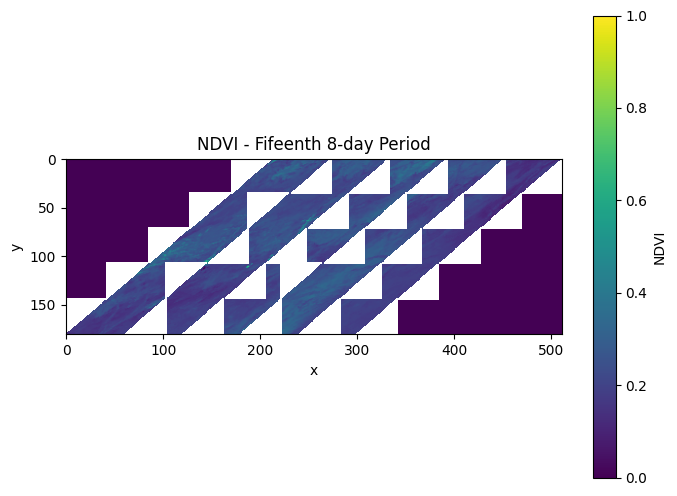

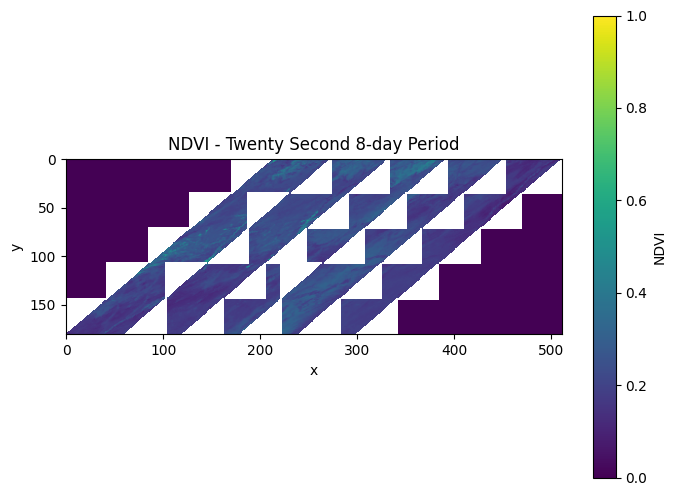

In [ ]:

# Plot the first 8-day NDVI layer
plt.figure(figsize=(8, 6))
plt.imshow(stacked_data[0, :, :], cmap="viridis", origin="upper", vmin=0, vmax=1)
plt.colorbar(label="NDVI")
plt.title("NDVI - First 8-day Period")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

plt.figure(figsize=(8, 6))
plt.imshow(stacked_data[15, :, :], cmap="viridis", origin="upper", vmin=0, vmax=1)
plt.colorbar(label="NDVI")
plt.title("NDVI - Fifeenth 8-day Period")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

plt.figure(figsize=(8, 6))
plt.imshow(stacked_data[22, :, :], cmap="viridis", origin="upper", vmin=0, vmax=1)
plt.colorbar(label="NDVI")
plt.title("NDVI - Twenty Second 8-day Period")
plt.xlabel("x")
plt.ylabel("y")
plt.show()


In [ ]:
## define the DLC model

def dlc_model(time, xmidS, scalS, xmidA, scalA):
    return (1 / (1 + np.exp((xmidS - time) / scalS))) - (1 / (1 + np.exp((xmidA - time) / scalA)))


Fit the curves to calculate IRG. For the sublette herd area, this takes ~15 minutes to get all the values for a single eyar.

In [114]:
# years = list(range(2018, 2024))  # Use 2024 as the end point to include 2023
years = [2018, 2019, 2020, 2021]
years = [2018]

## get the dates
dates = []
for year in years:
    start_date = datetime(year, 1, 1)
    dates.extend([start_date + timedelta(days=8 * i) for i in range(46)])  # 46 intervals in 365-day year

dates = pd.to_datetime(dates)

## intial parameters to try for the DLC
dlc_bounds = ([30, 1, 167, 1], [228, 30, 288, 35])

## run the function for each pixel seperately
def fit_dlc_per_pixel(ndvi_data, time, dlc_bounds):
    if np.isnan(ndvi_data).any() or len(ndvi_data[~np.isnan(ndvi_data)]) < 4:
        return [np.nan] * 8  # return NaNs if insufficient data

    try:
        ## initial parameter guesses
        initial_guess = [130, 10, 230, 17]
        
        ## perform the curve fitting
        popt, pcov = curve_fit(dlc_model, time, ndvi_data, p0=initial_guess, bounds=dlc_bounds)
        
        ## extract standard errors from the covariance matrix
        perr = np.sqrt(np.diag(pcov))
        
        ## return parameters and standard errors
        return list(popt) + list(perr)
    
    except Exception as e:
        print(f"Error fitting pixel: {e}")
        return [np.nan] * 8

## process the data for each year seperately
def fit_dlc_for_year(ndvi_stack, dates, years, dlc_bounds):
    results = []
    
    for year in years:
        # Subset NDVI data to current year
        year_indices = [i for i, date in enumerate(dates) if date.year == year]
        ndvi_year = ndvi_stack[year_indices]
        time = np.array([date.timetuple().tm_yday for i, date in enumerate(dates) if date.year == year])
        
        # Initialize result array for current year
        dlc_params = np.full((*ndvi_year.shape[1:], 8), np.nan)
        
        # Loop over each pixel
        for row in range(ndvi_year.shape[1]):
            for col in range(ndvi_year.shape[2]):
                ndvi_pixel = ndvi_year[:, row, col]
                dlc_params[row, col, :] = fit_dlc_per_pixel(ndvi_pixel, time, dlc_bounds)
                
        results.append(dlc_params)
    
    return np.stack(results, axis=0)  # Shape: (years, rows, cols, params)


## fit the DLC model for each year
dlc_results = fit_dlc_for_year(scaled_data, dates, years, dlc_bounds)

print("DLC Parameters Shape:", dlc_results.shape) ## years, rows, columns, parameters

Error fitting pixel: Optimal parameters not found: The maximum number of function evaluations is exceeded.
DLC Parameters Shape: (1, 34, 277, 8)


In [115]:
# Function to calculate fitted NDVI values for each pixel based on the DLC parameters
def calculate_fitted_vals(dlc_params, dates, values="daily"):
    time = np.arange(1, 366) if values == "daily" else np.arange(1, 366, 7)
    fitted_vals = np.full((dlc_params.shape[0], dlc_params.shape[1], len(time)), np.nan)
    
    for row in range(dlc_params.shape[0]):
        for col in range(dlc_params.shape[1]):
            params = dlc_params[row, col, :4]
            if np.isnan(params).any():
                continue  # Skip pixels with NaN parameters
            fitted_vals[row, col, :] = dlc_model(time, *params)
    
    return fitted_vals

# Function to calculate Instantaneous Rate of Green-up (IRG)
def calculate_irg(fitted_vals, sclIRG=True):
    # Calculate the difference along the time dimension (axis=2)
    irg = np.diff(fitted_vals, axis=2)
    
    # Pad the last day with NaN to keep the dimensions consistent
    irg = np.concatenate((irg, np.full(irg.shape[:-1] + (1,), np.nan)), axis=2)
    
    # Set negative IRG values to 0
    irg[irg < 0] = 0
    
    # Scale IRG values between 0 and 1 if required
    if sclIRG:
        irg_min = np.nanmin(irg)
        irg_max = np.nanmax(irg)
        if irg_max > irg_min:  # Prevent division by zero
            irg = (irg - irg_min) / (irg_max - irg_min)
    
    return irg


# Function to calculate max values and peak dates, with handling for all-NaN slices
def calculate_max_and_dates(values_array, time_points, func="max"):
    # Initialize arrays to hold results, filled with NaNs initially
    max_vals = np.full(values_array.shape[:2], np.nan)
    max_dates = np.full(values_array.shape[:2], np.nan)

    for row in range(values_array.shape[0]):
        for col in range(values_array.shape[1]):
            pixel_values = values_array[row, col, :]
            if np.isnan(pixel_values).all():
                continue  # Skip if all values are NaN for this pixel
            
            # Calculate max value and corresponding date
            max_vals[row, col] = np.nanmax(pixel_values)
            max_dates[row, col] = time_points[np.nanargmax(pixel_values)]
    
    return max_vals, max_dates

# Prepare time indices for date calculations
years = [2018, 2019, 2020, 2021]
years = [2018]
dates = []
for year in years:
    start_date = datetime(year, 1, 1)
    dates.extend([start_date + timedelta(days=8 * i) for i in range(46)])  # 46 intervals in 365-day year
dates = pd.to_datetime(dates)

# Calculate fitted values and IRG for year 2017
time_points = np.arange(1, 366)  # Day of year for daily calculations
fitted_vals = calculate_fitted_vals(dlc_results[0, :, :, :], dates)  # for year 1, e.g., 2017
irg_vals = calculate_irg(fitted_vals)

# Calculate max values and dates
max_ndvi, max_ndvi_date = calculate_max_and_dates(fitted_vals, time_points, func="max")
max_irg, max_irg_date = calculate_max_and_dates(irg_vals, time_points, func="max")

print("Max NDVI Value:", max_ndvi)
print("Max NDVI date:", max_ndvi_date)

print("Max IRG Value:", max_irg)
print("Max IRG Date:", max_irg_date)



Max NDVI Value: [[0.78401392 0.78401392 0.78401392 ... 0.5747968  0.57303939 0.55657178]
 [0.50283107 0.49699108 0.47433133 ... 0.5469254  0.56375252 0.53809842]
 [0.76287559 0.76287559 0.35898847 ... 0.54443799 0.54443799 0.29817538]
 ...
 [0.76189847 0.76189847 0.78401392 ... 0.6187614  0.54545408 0.71503781]
 [0.49303284 0.78401371 0.9630342  ... 0.57560498 0.57560498 0.63206905]
 [0.89063372 0.74097941 0.51691786 ... 0.55329258 0.54611024 0.6197741 ]]
Max NDVI date: [[ 96.  96.  96. ... 261. 261. 262.]
 [263. 263. 263. ... 262. 262. 263.]
 [100. 100. 142. ... 262. 262. 154.]
 ...
 [100. 100.  96. ... 249. 255. 229.]
 [255.  96. 152. ... 254. 254. 242.]
 [191. 104. 253. ... 249. 256. 241.]]
Max IRG Value: [[0.14059326 0.14059326 0.14059326 ... 0.22148036 0.21907599 0.19783327]
 [0.14264138 0.13767401 0.11976357 ... 0.18652183 0.20685586 0.17675922]
 [0.13873569 0.13873569 0.0808652  ... 0.18372675 0.18372675 0.06723406]
 ...
 [0.13864798 0.13864798 0.14059326 ... 0.16535271 0.134515

Latitude: 37.272884, Longitude: -112.850987 -> Row: -6, Col: -39


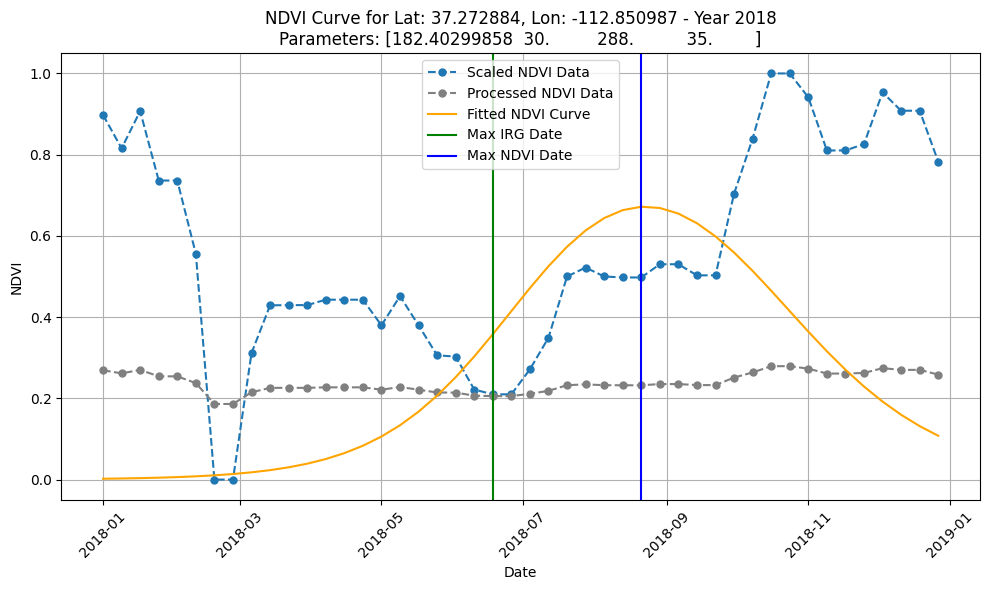

Latitude: 37.092615, Longitude: -112.974834 -> Row: 34, Col: -66


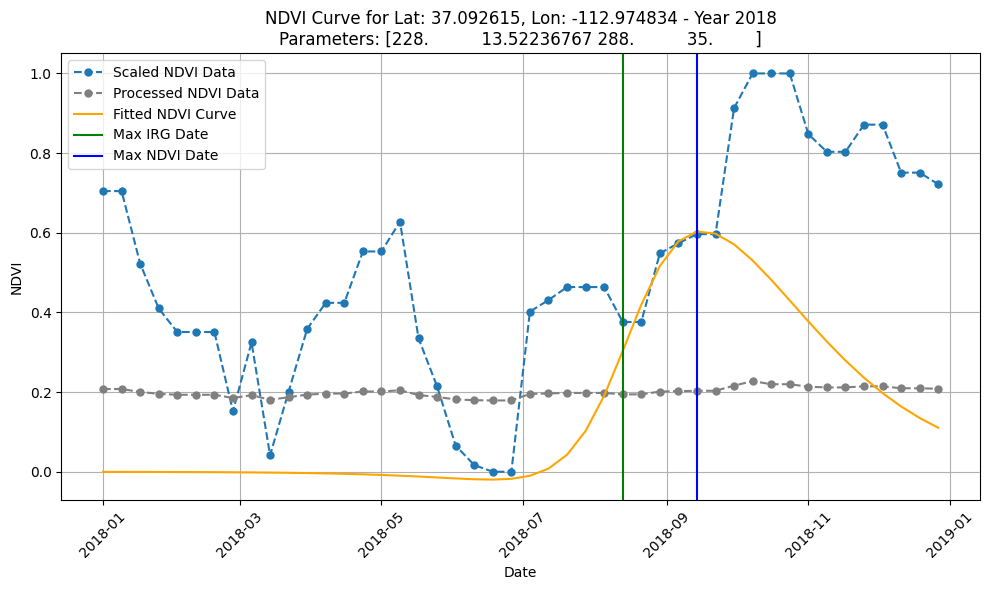

Latitude: 37.112968, Longitude: -112.338641 -> Row: 30, Col: 76


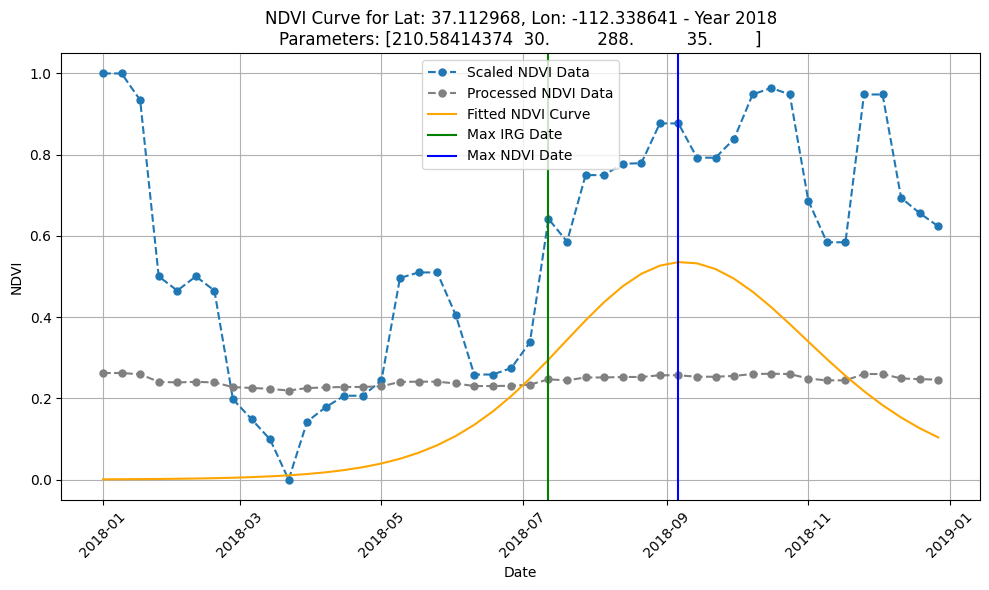

In [ ]:
from rasterio.transform import rowcol

# Function to calculate fitted NDVI values for specific dates
def calculate_fitted_ndvi(dlc_params, time_points):
    return dlc_model(time_points, *dlc_params)

# Updated function to plot NDVI and curves for a specific latitude and longitude
def plot_ndvi_latlon(dlc_results, stacked_data, scaled_data, dates, lat, lon, transform, years):
    # Convert latitude and longitude to row and column indices
    row, col = rowcol(transform, lon, lat)
    print(f"Latitude: {lat}, Longitude: {lon} -> Row: {row}, Col: {col}")
    
    # Plotting setup
    fig, ax = plt.subplots(len(years), 1, figsize=(10, 6 * len(years)))
    if len(years) == 1:
        ax = [ax]  # Ensure ax is always a list for easy indexing
    
    for i, year in enumerate(years):
        # Extract parameters for the current year and pixel
        params = dlc_results[i, row, col, :4]  # First 4 values are the fitted parameters
        
        # Get the dates and time points for 8-day intervals
        year_dates = np.array([date for date in dates if date.year == year])
        time_points = np.array([date.timetuple().tm_yday for date in year_dates])
        
        # Generate fitted curve if parameters are valid
        if not np.isnan(params).any():
            fitted_curve = calculate_fitted_ndvi(params, time_points)
            
            # Calculate IRG and find max dates (for 8-day intervals)
            irg_vals = np.diff(fitted_curve)
            max_irg_idx = np.nanargmax(irg_vals)
            max_ndvi_idx = np.nanargmax(fitted_curve)
            
            max_irg_date = year_dates[max_irg_idx]
            max_ndvi_date = year_dates[max_ndvi_idx]
        else:
            fitted_curve = None
            max_irg_date = max_ndvi_date = None
            print(f"No valid parameters for pixel ({row}, {col}) in {year}")
        
        # Extract raw NDVI values for the current year and pixel
        year_indices = [j for j, date in enumerate(dates) if date.year == year]
        ndvi_values = scaled_data[year_indices, row, col]
        ndvi_values_raw = stacked_data[year_indices, row, col]
        
        # Plot raw NDVI data
        ax[i].plot(year_dates, ndvi_values, 'o', label="Scaled NDVI Data", linestyle='--', markersize=5)
        ax[i].plot(year_dates, ndvi_values_raw, 'o', label="Processed NDVI Data", linestyle='--', markersize=5, color = "grey")
        
        # Plot fitted DLC curve if available
        if fitted_curve is not None:
            ax[i].plot(year_dates, fitted_curve, label="Fitted NDVI Curve", color='orange')
            ax[i].set_title(f"NDVI Curve for Lat: {lat}, Lon: {lon} - Year {year}\nParameters: {params}")
            
            # Plot vertical lines at max IRG and max NDVI dates
            if max_irg_date is not None:
                ax[i].axvline(max_irg_date, color='green', linestyle='-', label="Max IRG Date")
            if max_ndvi_date is not None:
                ax[i].axvline(max_ndvi_date, color='blue', linestyle='-', label="Max NDVI Date")
        else:
            ax[i].set_title(f"NDVI Curve for Lat: {lat}, Lon: {lon} - Year {year} (No Fit)")
        
        # Formatting
        ax[i].set_xlabel("Date")
        ax[i].set_ylabel("NDVI")
        ax[i].legend()
        ax[i].grid(True)
        ax[i].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()


## Some weird places in WY that were different than jerod's code
# -110.0903 42.23412
# -109.2682 42.47383

latitude =  37.272884  # Replace with your latitude
longitude = -112.850987  # Replace with your longitude
transform = mosaic_att.attrs["transform"]  # Use the transform from your mosaic

# Plot NDVI for the given latitude and longitude
plot_ndvi_latlon(dlc_results, stacked_data, scaled_data, dates, latitude, longitude, transform, years)

latitude = 37.092615  # Replace with your latitude
longitude = -112.974834  # Replace with your longitude

# Plot NDVI for the given latitude and longitude
plot_ndvi_latlon(dlc_results, stacked_data, scaled_data, dates, latitude, longitude, transform, years)

latitude =    37.112968  # Replace with your latitude
longitude = -112.338641 # Replace with your longitude

# Plot NDVI for the given latitude and longitude
plot_ndvi_latlon(dlc_results, stacked_data, scaled_data, dates, latitude, longitude, transform, years)


In [88]:
# Function to calculate fitted NDVI values for specific dates
def calculate_fitted_ndvi(dlc_params, time_points):
    return dlc_model(time_points, *dlc_params)

# Updated function to plot NDVI and curves for a specific latitude and longitude
def plot_ndvi_latlon(dlc_results, stacked_data, scaled_data, dates, row, col, years):

    # Plotting setup
    fig, ax = plt.subplots(len(years), 1, figsize=(10, 6 * len(years)))
    if len(years) == 1:
        ax = [ax]  # Ensure ax is always a list for easy indexing
    
    for i, year in enumerate(years):
        # Extract parameters for the current year and pixel
        params = dlc_results[i, row, col, :4]  # First 4 values are the fitted parameters
        
        # Get the dates and time points for 8-day intervals
        year_dates = np.array([date for date in dates if date.year == year])
        time_points = np.array([date.timetuple().tm_yday for date in year_dates])
        
        # Generate fitted curve if parameters are valid
        if not np.isnan(params).any():
            fitted_curve = calculate_fitted_ndvi(params, time_points)
            
            # Calculate IRG and find max dates (for 8-day intervals)
            irg_vals = np.diff(fitted_curve)
            max_irg_idx = np.nanargmax(irg_vals)
            max_ndvi_idx = np.nanargmax(fitted_curve)
            
            max_irg_date = year_dates[max_irg_idx]
            max_ndvi_date = year_dates[max_ndvi_idx]
        else:
            fitted_curve = None
            max_irg_date = max_ndvi_date = None
            print(f"No valid parameters for pixel ({row}, {col}) in {year}")
        
        # Extract raw NDVI values for the current year and pixel
        year_indices = [j for j, date in enumerate(dates) if date.year == year]
        ndvi_values = scaled_data[year_indices, row, col]
        ndvi_values_raw = stacked_data[year_indices, row, col]
        
        # Plot raw NDVI data
        ax[i].plot(year_dates, ndvi_values, 'o', label="Scaled NDVI Data", linestyle='--', markersize=5)
        ax[i].plot(year_dates, ndvi_values_raw, 'o', label="Processed NDVI Data", linestyle='--', markersize=5, color = "grey")
        
        # Plot fitted DLC curve if available
        if fitted_curve is not None:
            ax[i].plot(year_dates, fitted_curve, label="Fitted NDVI Curve", color='orange')
            ax[i].set_title(f"NDVI Curve for Lat: {row}, Lon: {col} - Year {year}\nParameters: {params}")
            
            # Plot vertical lines at max IRG and max NDVI dates
            if max_irg_date is not None:
                ax[i].axvline(max_irg_date, color='green', linestyle='-', label="Max IRG Date")
            if max_ndvi_date is not None:
                ax[i].axvline(max_ndvi_date, color='blue', linestyle='-', label="Max NDVI Date")
        else:
            ax[i].set_title(f"NDVI Curve for Lat: {row}, Lon: {col} - Year {year} (No Fit)")
        
        # Formatting
        ax[i].set_xlabel("Date")
        ax[i].set_ylabel("NDVI")
        ax[i].legend()
        ax[i].grid(True)
        ax[i].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()


# -110.0903 42.23412
row =  25  # Replace with your latitude
col = 210  # Replace with your longitude
transform = mosaic_att.attrs["transform"]  # Use the transform from your mosaic

# Plot NDVI for the given latitude and longitude
plot_ndvi_latlon(dlc_results, stacked_data, scaled_data, dates, row, col, years)

NameError: name 'dlc_results' is not defined

In [96]:
print("Attributes:", mosaic_att.attrs)  # CRS, transform, etc.

def export_max_irg_raster(max_irg, max_irg_date, mosaic_att, output_file):
    """
    Export a raster with two bands: max IRG value and max IRG day.

    Parameters:
    - max_irg: 2D NumPy array with max IRG values (rows, cols)
    - max_irg_date: 2D NumPy array with max IRG dates (rows, cols)
    - mosaic_att: Reference xarray.Dataset containing CRS and extent metadata
    - output_file: Full path to the output GeoTIFF file
    """
    # Extract CRS and transform from mosaic_att
    crs = mosaic_att.attrs.get("crs", None)
    transform = mosaic_att.attrs.get("transform", None)

    if crs is None or transform is None:
        raise ValueError("CRS and transform metadata must be present in the mosaic_att attributes.")

    # Determine raster dimensions
    height, width = max_irg.shape

    # Prepare metadata
    meta = {
        "driver": "GTiff",
        "height": height,
        "width": width,
        "count": 2,  # Two bands: max IRG value and max IRG day
        "dtype": "float32",  # Data type
        "crs": crs,  # CRS from mosaic_att
        "transform": transform,  # Transform from mosaic_att
    }

    # Create a 3D array for export
    combined_data = np.stack([max_irg, max_irg_date], axis=0)  # Shape: (2, rows, cols)

    # Write to GeoTIFF
    with rasterio.open(output_file, "w", **meta) as dst:
        dst.write(combined_data[0, :, :], 1)  # Band 1: Max IRG value
        dst.write(combined_data[1, :, :], 2)  # Band 2: Max IRG day

    print(f"Raster exported successfully to {output_file}")


# Example usage
output_folder = "H:/My Drive/IRG_Exports"
os.makedirs(output_folder, exist_ok=True)

output_file = os.path.join(output_folder, "Max_IRG_2018.tif")

# Call the export function
export_max_irg_raster(max_irg, max_irg_date, mosaic_att, output_file)


Attributes: {'crs': 'EPSG:4326', 'extent': (-110.80269871972239, 41.72225337093118, -108.65123361425613, 43.41108610507588), 'transform': Affine(0.0044915764205976155, 0.0, -110.80269871972239,
       0.0, -0.004491576420597616, 43.41108610507588)}
Raster exported successfully to H:/My Drive/IRG_Exports\Max_IRG_2018.tif
